# Extending the named method registry

A named catalog is a finite map from accepted names to construction rules:

$$
\mathcal R=\{k\mapsto F_k:k\in\mathcal K\},
\qquad x=F_{\pi(a)}(q).
$$

Here, $\mathcal K$ is the set of standard names, $F_k$ is the construction rule stored under name $k$, $a$ is a supplied standard or alternate name, $\pi(a)$ resolves it to a standard name, $q$ contains the supplied settings, and $x$ is the constructed object.

,Method family,Available methods,Plain description
0,Bars,6,Methods supplied with the library
1,Cross-validation,6,Methods supplied with the library
2,Feature importance,5,Methods supplied with the library
3,Labels implemented as classes,0,Open extension family
4,Position sizes,0,Open extension family
5,Portfolio methods,0,Open extension family


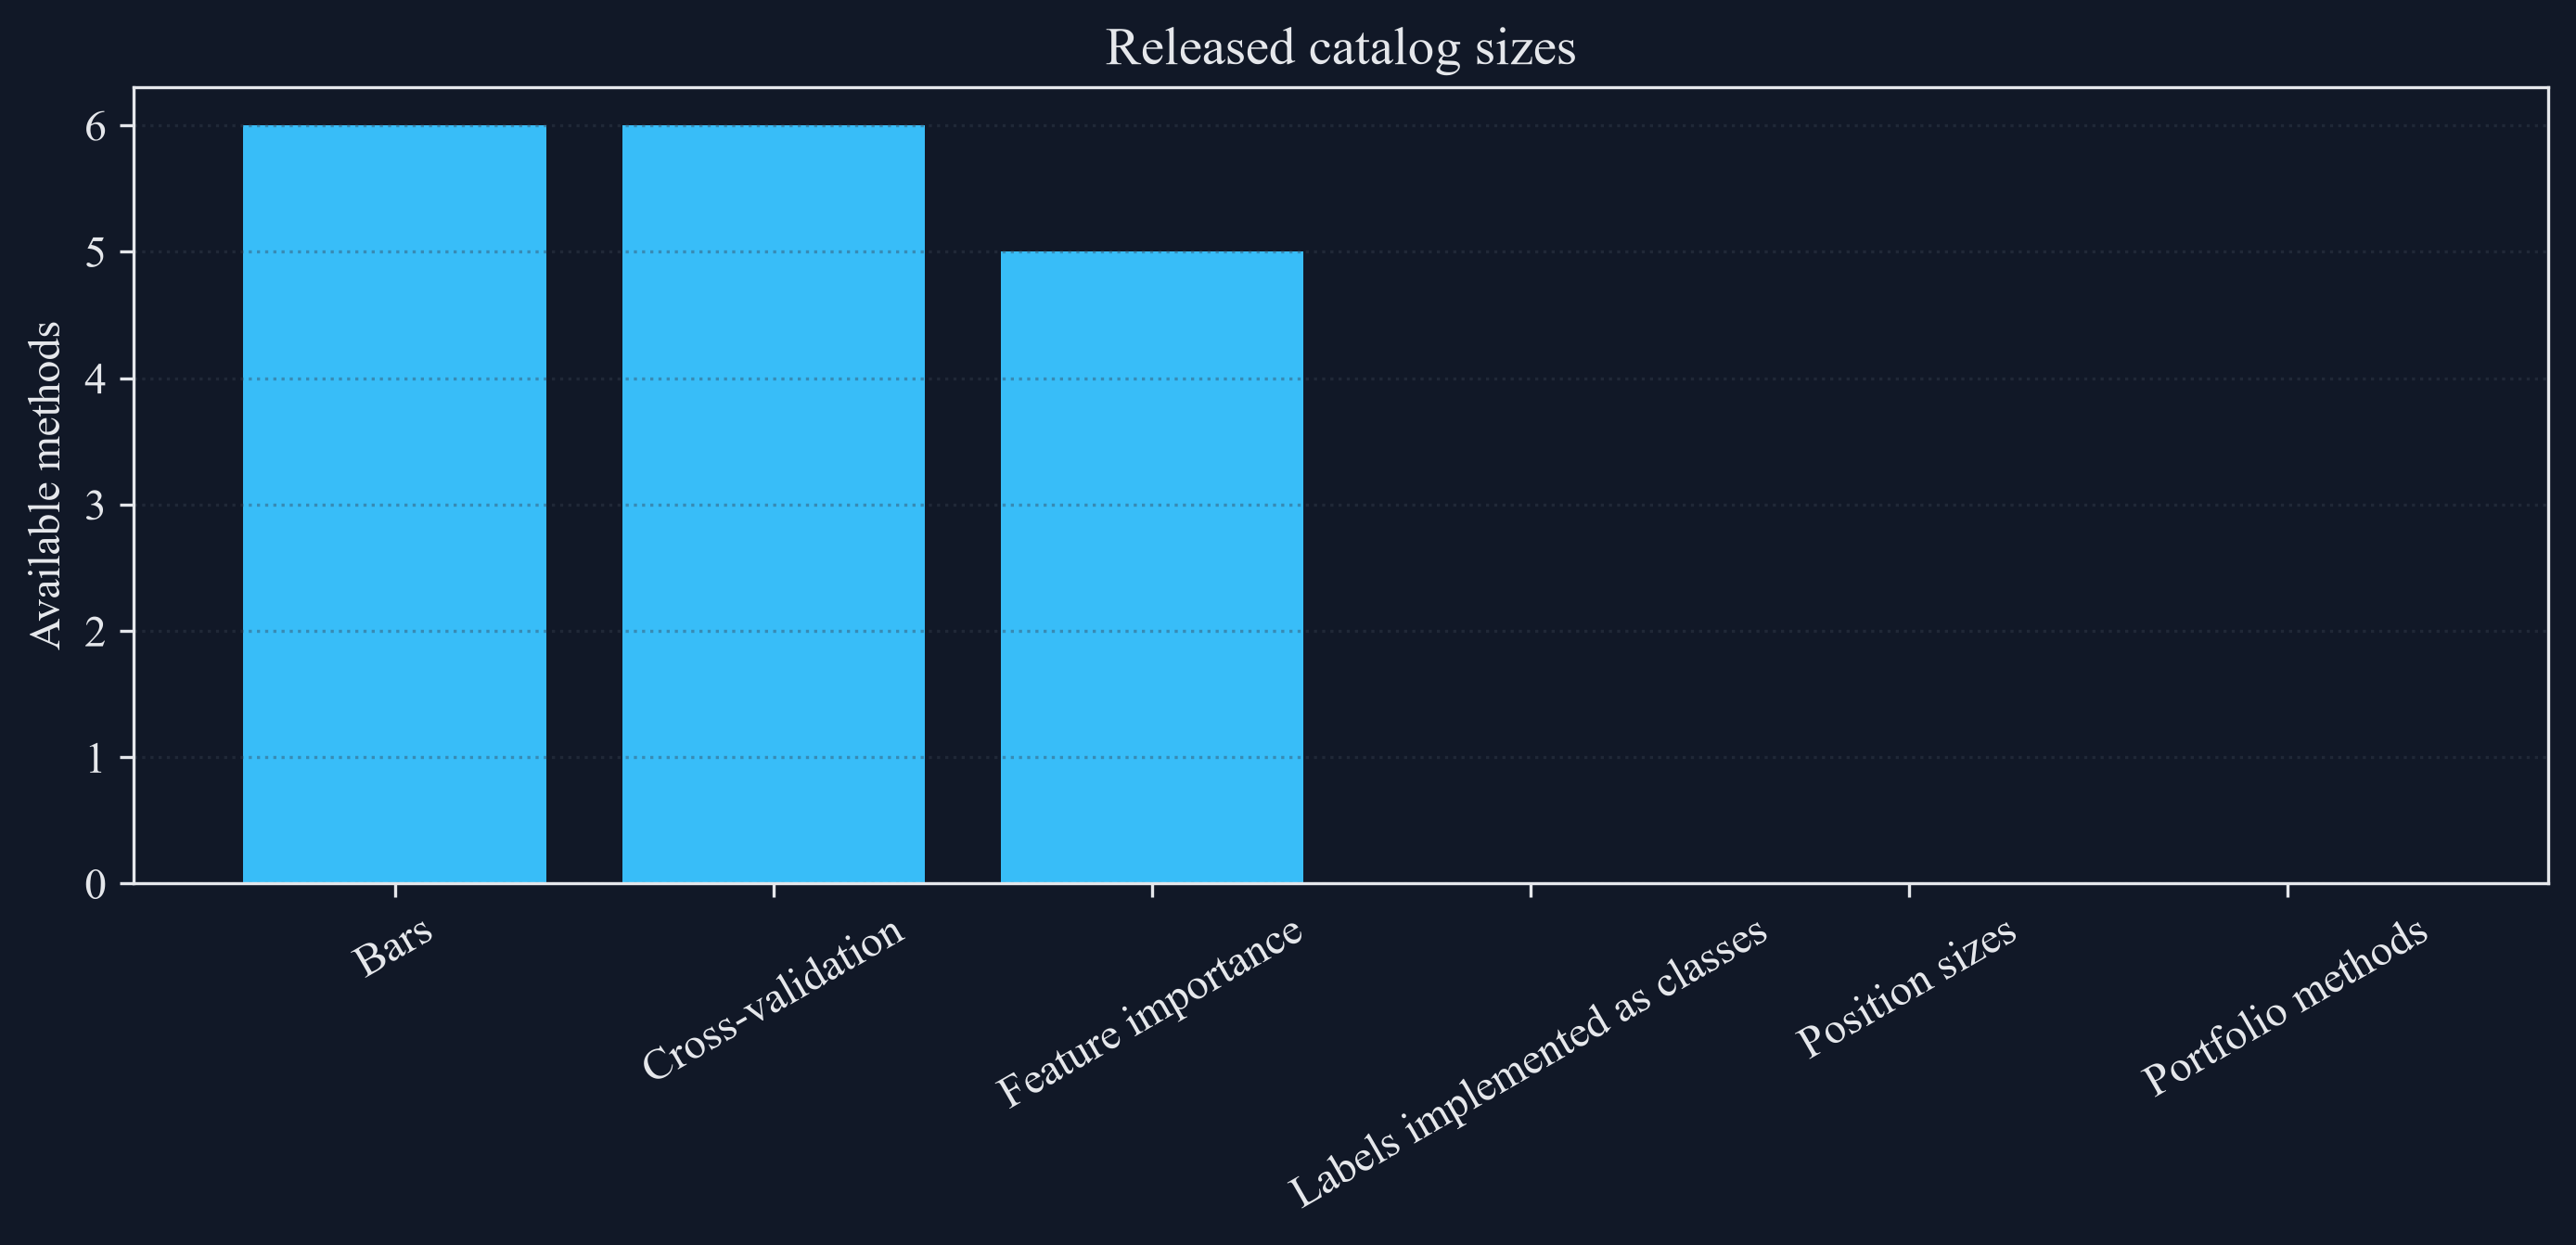

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import inspect
import io
import sys
import time
import warnings
import zipfile
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_config
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
from RiskLabAI.hpc import linear_partitions, nested_partitions, mp_pandas_obj, parallel_run, process_jobs, process_jobs_sequential
from RiskLabAI.core import BARS, BET_SIZERS, CROSS_VALIDATORS, FEATURE_IMPORTANCE, LABELERS, PORTFOLIO_OPTIMIZERS, BaseLabeler, Registry, list_components
from RiskLabAI.controller.bars_initializer import BarsInitializerController
from RiskLabAI.controller.data_structure_controller import BAR_COLUMNS, Controller
from RiskLabAI.optimization.hrp import hrp, inverse_variance_weights
FIGURES = ROOT / 'outputs' / 'figures' / '32_reproducible_research_study'
TABLES = ROOT / 'outputs' / 'tables' / '32_reproducible_research_study'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return '0'
    return f'{value:.6f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', display_float)

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: 'Yes', False: 'No'})
    table_frame.to_csv(TABLES / f'{stem}.csv', index=False, float_format=compact_float_format('%.10f'))
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='tbp'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{adjustbox}{max width=\\textwidth}' + '\n' + '\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}' + '\n' + '\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)

def load_french_returns():
    data_path = ROOT / 'data' / 'public' / 'ken_french' / '49_Industry_Portfolios_daily_CSV.zip'
    assert data_path.is_file()
    with zipfile.ZipFile(data_path) as archive:
        archive_name = archive.namelist()[0]
        public_lines = archive.read(archive_name).decode('latin1').splitlines()
    header_row = next((index for index, line in enumerate(public_lines) if line.startswith(',Agric')))
    end_row = next((index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip()))
    raw_frame = pd.read_csv(io.StringIO('\n'.join(public_lines[header_row:end_row])))
    raw_frame = raw_frame.rename(columns={raw_frame.columns[0]: 'Date'})
    raw_frame['Date'] = pd.to_datetime(raw_frame['Date'].astype(str), format='%Y%m%d')
    returns = raw_frame.set_index('Date').replace([-99.99, -999.0], np.nan) / 100.0
    returns = returns.loc['2019-01-01':'2025-12-31'].dropna().copy()
    return (returns, data_path)

def load_binance_rows(record_limit=5000):
    data_path = ROOT / 'data' / 'public' / 'binance' / 'BTCUSDT-1m-2021-01.zip'
    assert data_path.is_file()
    columns = ['Open time', 'Open', 'High', 'Low', 'Close', 'Volume', 'Close time', 'Quote volume', 'Trades', 'Buyer base volume', 'Buyer quote volume', 'Unused']
    raw_frame = pd.read_csv(data_path, compression='zip', header=None, names=columns, nrows=record_limit)
    times = pd.to_datetime(raw_frame['Open time'], unit='ms', utc=True).dt.tz_convert(None)
    rows = pd.DataFrame({'Date Time': times, 'Price': raw_frame['Close'].astype(float), 'Volume': raw_frame['Volume'].astype(float)})
    return (rows, data_path)

def annualized_volatility(returns):
    return float(returns.std(ddof=1) * np.sqrt(252.0))

def maximum_drawdown(returns):
    wealth = (1.0 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1.0
    return float(drawdown.min())

def portfolio_weights(method, covariance, correlation):
    if method == 'Equal weight':
        return pd.Series(1.0 / len(covariance), index=covariance.index)
    if method == 'Inverse variance':
        return pd.Series(inverse_variance_weights(covariance), index=covariance.index)
    if method == 'Hierarchical risk parity':
        return hrp(covariance, correlation).reindex(covariance.index)
    raise KeyError(method)

def portfolio_record(method, weights, returns):
    path = returns @ weights.reindex(returns.columns)
    concentration = float(np.square(weights).sum())
    return {'Method': method, 'Observations': len(path), 'Annual mean return': float(path.mean() * 252.0), 'Annual volatility': annualized_volatility(path), 'Return to volatility': float(path.mean() / path.std(ddof=1) * np.sqrt(252.0)), 'Maximum drawdown': maximum_drawdown(path), 'Largest weight': float(weights.max()), 'Weight concentration': concentration, 'Effective holdings': float(1.0 / concentration)}
catalogue = list_components()
family_labels = {'bars': 'Bars', 'cross_validators': 'Cross-validation', 'feature_importance': 'Feature importance', 'labelers': 'Labels implemented as classes', 'bet_sizers': 'Position sizes', 'portfolio_optimizers': 'Portfolio methods'}
catalogue_rows = []
for family, names in catalogue.items():
    catalogue_rows.append({'Method family': family_labels[family], 'Available methods': len(names), 'Plain description': 'Methods supplied with the library' if names else 'Open extension family'})
catalogue_table = pd.DataFrame(catalogue_rows)
save_table(catalogue_table, 'catalogue_counts', 'Released named method families and their current counts.', 'tab:chapter30-catalogue-counts')
display(catalogue_table)
figure, axis = plt.subplots(figsize=(9.4, 4.6))
colors = [palette['cyan'] if value else palette['muted'] for value in catalogue_table['Available methods']]
axis.bar(catalogue_table['Method family'], catalogue_table['Available methods'], color=colors)
axis.set_ylabel('Available methods')
axis.set_title('Released catalog sizes')
axis.tick_params(axis='x', rotation=30)
axis.grid(True, axis='y', alpha=0.4)
figure.tight_layout()
save_figure(figure, 'catalogue_counts')
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Sixteen Bar Choices

The controller chooses one construction rule from its accepted name set:

$$
B(a,q)=F_{\pi(a)}(q),
\qquad a\in\mathcal K_{\mathrm{bar}}.
$$

Here, $a$ is an accepted bar name, $\mathcal K_{\mathrm{bar}}$ is the controller's set of sixteen names, $q$ contains the method settings, $\pi$ resolves the name, $F$ is the selected construction rule, and $B(a,q)$ is the resulting bar object.

,Order,Bar choice,Family,Constructed class
0,1,Expected Dollar Imbalance Bars,Imbalance,Expected imbalance bars
1,2,Expected Volume Imbalance Bars,Imbalance,Expected imbalance bars
2,3,Expected Tick Imbalance Bars,Imbalance,Expected imbalance bars
3,4,Fixed Dollar Imbalance Bars,Imbalance,Fixed imbalance bars
4,5,Fixed Volume Imbalance Bars,Imbalance,Fixed imbalance bars
5,6,Fixed Tick Imbalance Bars,Imbalance,Fixed imbalance bars
6,7,Expected Dollar Run Bars,Run,Expected run bars
7,8,Expected Volume Run Bars,Run,Expected run bars
8,9,Expected Tick Run Bars,Run,Expected run bars
9,10,Fixed Dollar Run Bars,Run,Fixed run bars


,Family,Choices
0,Imbalance,6
1,Run,6
2,Standard,3
3,Time,1


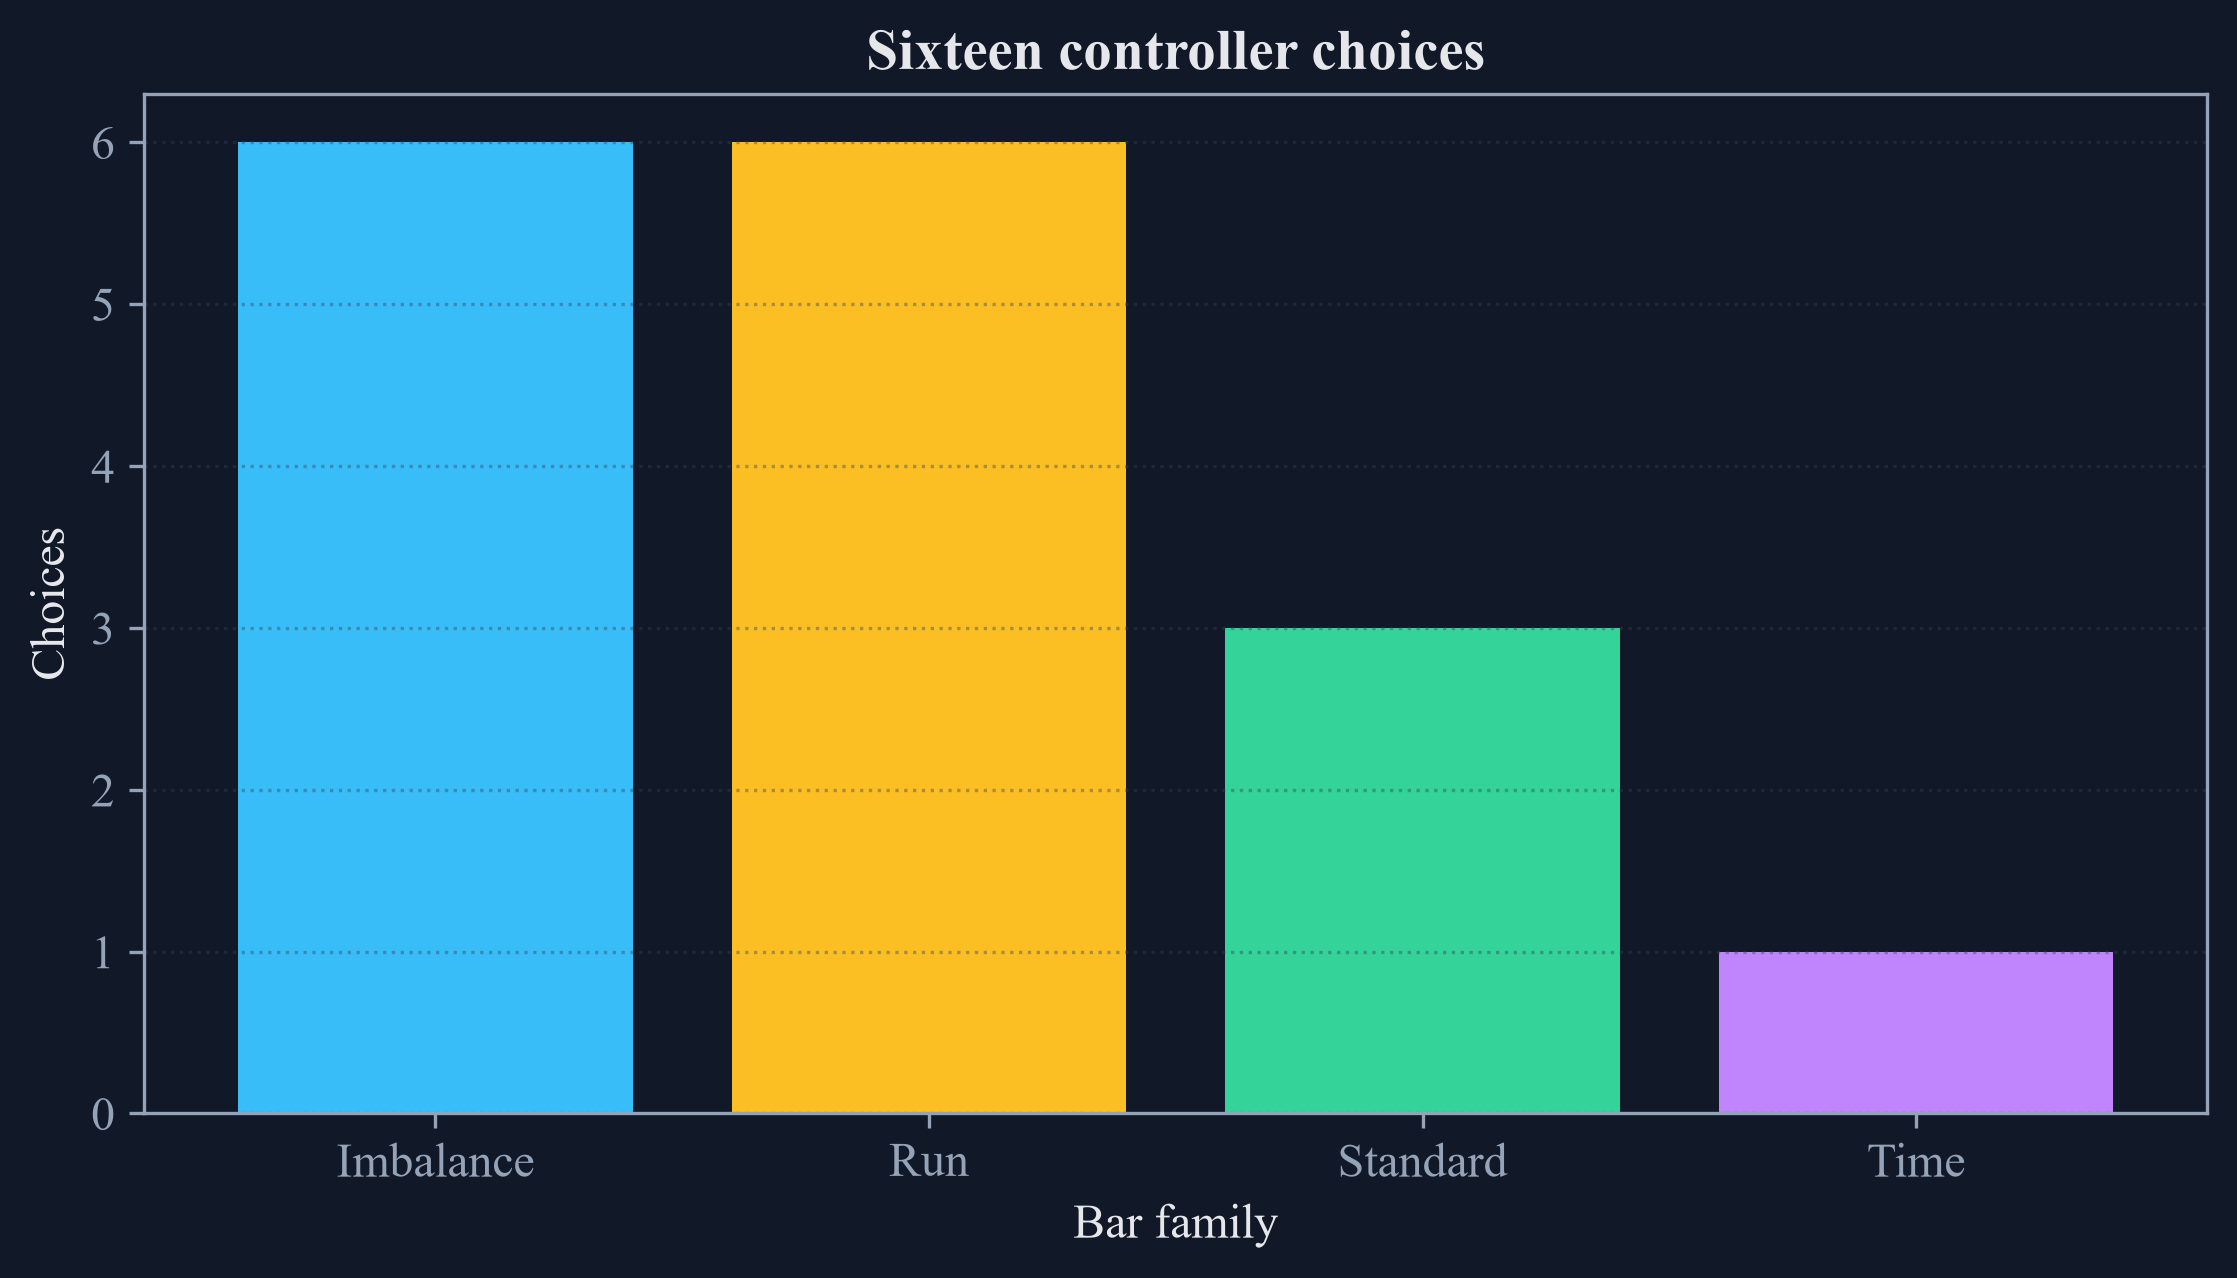

In [2]:
bar_controller = BarsInitializerController()
bar_names = list(bar_controller.method_name_to_method)

def bar_family(name):
    if "imbalance" in name:
        return "Imbalance"
    if "run" in name:
        return "Run"
    if "standard" in name:
        return "Standard"
    return "Time"

class_labels = {"ExpectedImbalanceBars": "Expected imbalance bars", "FixedImbalanceBars": "Fixed imbalance bars", "ExpectedRunBars": "Expected run bars", "FixedRunBars": "Fixed run bars", "StandardBars": "Standard bars", "TimeBars": "Time bars"}

method_rows = []
for name in bar_names:
    method = bar_controller.method_name_to_method[name]
    instance = method()
    method_rows.append({"Order": len(method_rows) + 1, "Bar choice": name.replace("_", " ").title(), "Family": bar_family(name), "Constructed class": class_labels[type(instance).__name__]})
bar_method_table = pd.DataFrame(method_rows)
family_count_table = bar_method_table.groupby("Family", as_index=False).size().rename(columns={"size": "Choices"})
save_table(bar_method_table, "bar_method_choices", "The sixteen controller choices with plain labels.", "tab:chapter30-bar-choices")
save_table(family_count_table, "bar_family_counts", "Counts of controller choices by bar family.", "tab:chapter30-bar-family-counts")
display(bar_method_table)
display(family_count_table)

figure, axis = plt.subplots(figsize=(7.6, 4.4))
axis.bar(family_count_table["Family"], family_count_table["Choices"], color=[palette["cyan"], palette["amber"], palette["green"], palette["violet"]])
axis.set_xlabel("Bar family")
axis.set_ylabel("Choices")
axis.set_title("Sixteen controller choices")
axis.grid(True, axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "bar_family_counts")

## A New Class Based Label

A fixed horizon label uses the sign of a future return:

$$
\ell_t=\operatorname{sign}\!\left(\frac{P_{t+h}}{P_t}-1\right).
$$

Here, $P_t$ is the price at observation $t$, $h$ is the chosen horizon measured in observations, $P_{t+h}/P_t-1$ is the forward return, and $\ell_t$ is minus one, zero, or one according to its sign.

,Stage,Standard name available,Alternate name available
0,Register,True,True
1,Create by alternate name,True,True
2,Reject duplicate,True,True
3,Remove,False,False


,Label,Observations,Meaning
0,-1,2431,Lower after three minutes
1,0,3,Equal or unavailable
2,1,2566,Higher after three minutes


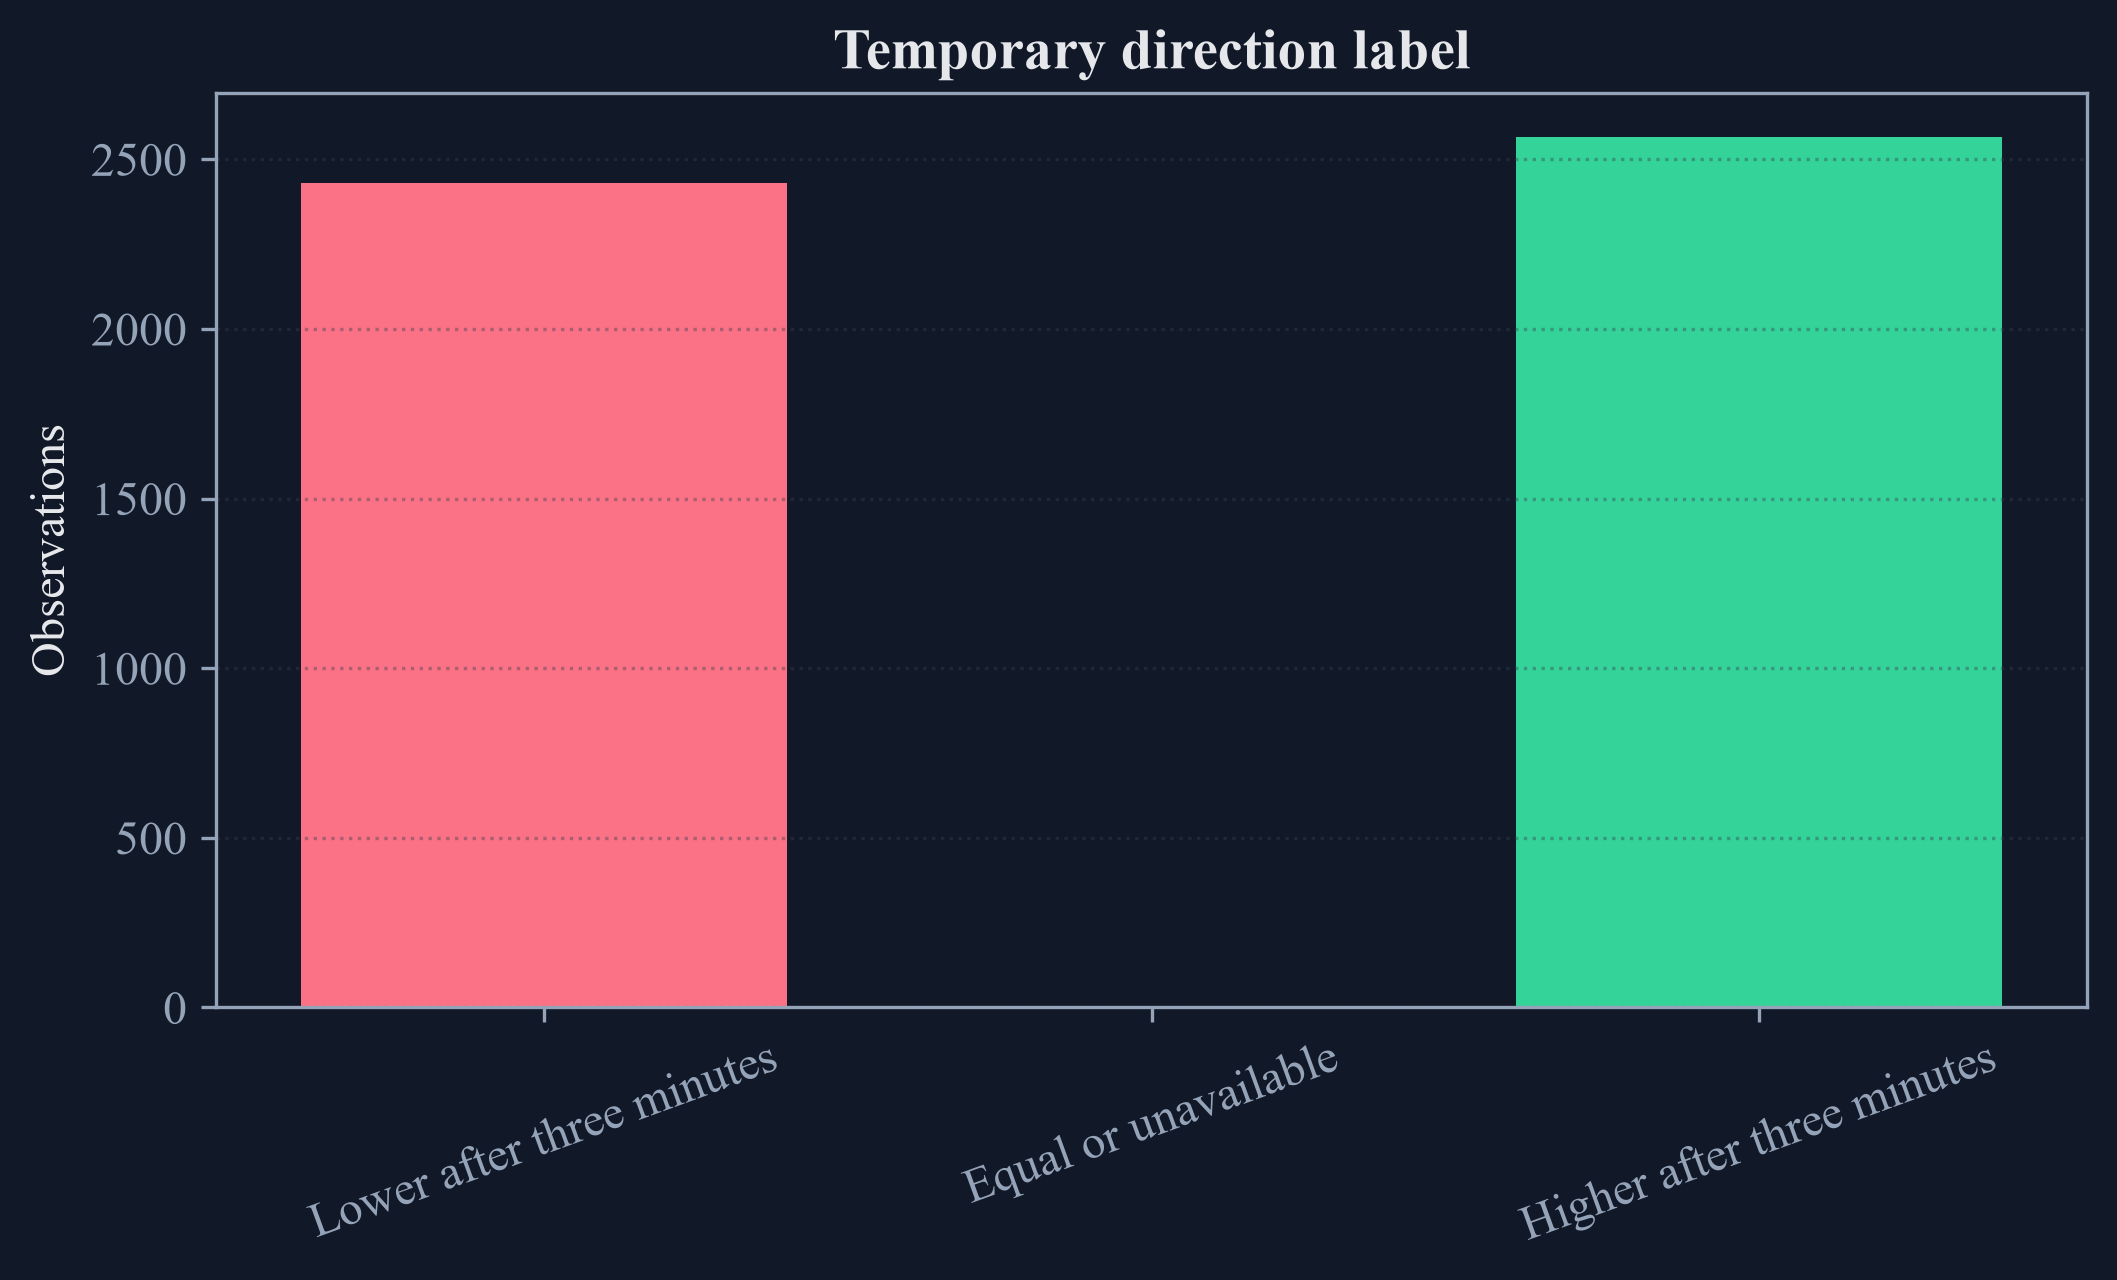

In [3]:
binance_rows, binance_path = load_binance_rows(5000)

class DirectionLabeler(BaseLabeler):

    def __init__(self, horizon=5):
        self.horizon = int(horizon)

    def label(self, prices, events=None, **kwargs):
        forward_return = prices.shift(-self.horizon) / prices - 1.0
        labels = np.sign(forward_return).fillna(0).astype(int)
        return pd.DataFrame({'Direction label': labels, 'Forward return': forward_return})
lifecycle_rows = []
LABELERS.register('direction_label', DirectionLabeler, aliases=('future_direction',), metadata={'family': 'labeling', 'horizon unit': 'observations'})
lifecycle_rows.append({'Stage': 'Register', 'Standard name available': 'direction_label' in LABELERS, 'Alternate name available': 'future_direction' in LABELERS})
labeler = LABELERS.create('FUTURE_DIRECTION', horizon=3, unused_value=99, filter_unknown_kwargs=True)
labels = labeler.label(binance_rows['Price'])
lifecycle_rows.append({'Stage': 'Create by alternate name', 'Standard name available': 'direction_label' in LABELERS, 'Alternate name available': 'future_direction' in LABELERS})
duplicate_blocked = False
try:
    LABELERS.register('direction_label', DirectionLabeler)
except KeyError:
    duplicate_blocked = True
lifecycle_rows.append({'Stage': 'Reject duplicate', 'Standard name available': duplicate_blocked, 'Alternate name available': duplicate_blocked})
label_metadata = LABELERS.metadata('future_direction')
LABELERS.unregister('direction_label')
lifecycle_rows.append({'Stage': 'Remove', 'Standard name available': 'direction_label' in LABELERS, 'Alternate name available': 'future_direction' in LABELERS})
lifecycle_table = pd.DataFrame(lifecycle_rows)
label_summary = labels['Direction label'].value_counts().sort_index().rename_axis('Label').reset_index(name='Observations')
label_summary['Meaning'] = label_summary['Label'].map({-1: 'Lower after three minutes', 0: 'Equal or unavailable', 1: 'Higher after three minutes'})
save_table(lifecycle_table, 'custom_label_lifecycle', 'Registration, creation, duplicate protection, and removal for a temporary label method.', 'tab:chapter30-label-lifecycle')
save_table(label_summary, 'custom_label_summary', 'Three-minute direction labels from the public minute records.', 'tab:chapter30-label-summary')
display(lifecycle_table)
display(label_summary)
figure, axis = plt.subplots(figsize=(7.2, 4.4))
axis.bar(label_summary['Meaning'], label_summary['Observations'], color=[palette['rose'], palette['muted'], palette['green']])
axis.set_ylabel('Observations')
axis.set_title('Temporary direction label')
axis.tick_params(axis='x', rotation=20)
axis.grid(True, axis='y', alpha=0.4)
figure.tight_layout()
save_figure(figure, 'custom_label_counts')


## Comparing eager construction with delayed construction

A delayed entry changes state only when its construction rule is first requested:

$$
Z_k^{\mathrm{before}}=1,
\qquad Z_k^{\mathrm{after}}=0.
$$

Here, $k$ is the standard name of a catalog entry, $Z_k=1$ means that its construction rule has not yet been resolved, and $Z_k=0$ means that the rule has been loaded after the first request.

In [4]:
class ScaleValue:
    def __init__(self, factor=1.0):
        self.factor = float(factor)

    def apply(self, value):
        return self.factor * value

temporary_catalog = Registry("chapter examples")
temporary_catalog.register("scale", ScaleValue, aliases=("multiply",), metadata={"family": "arithmetic"})
direct_object = temporary_catalog.create("MULTIPLY", factor=2.5, ignored=10, filter_unknown_kwargs=True)
temporary_catalog.register_lazy("counter", "collections:Counter", metadata={"family": "counting"})
lazy_before = temporary_catalog.is_lazy("counter")
counted = temporary_catalog.create("counter", "abracadabra")
lazy_after = temporary_catalog.is_lazy("counter")
registry_check_table = pd.DataFrame({"Check": ["Direct construction", "Alternate name", "Unknown setting removed", "Metadata retained", "Delayed before request", "Delayed after request", "Delayed result"], "Observed result": [direct_object.apply(4.0), "multiply resolves to scale", "Object created", temporary_catalog.metadata("scale")["family"], lazy_before, lazy_after, counted["a"]], "Expected result": [10.0, "multiply resolves to scale", "Object created", "arithmetic", True, False, 5]})
save_table(registry_check_table, "registry_construction_checks", "Direct, alternate-name, filtered, metadata, and delayed construction checks.", "tab:chapter30-registry-checks")
display(registry_check_table)

,Check,Observed result,Expected result
0,Direct construction,10,10
1,Alternate name,multiply resolves to scale,multiply resolves to scale
2,Unknown setting removed,Object created,Object created
3,Metadata retained,arithmetic,arithmetic
4,Delayed before request,True,True
5,Delayed after request,False,False
6,Delayed result,5,5


## Public Bar Calculation Across Input Batches

A dollar bar ends at the first input row whose accumulated dollar value reaches the threshold:

$$
\tau_k=\inf\left\{n>\tau_{k-1}:\sum_{i=\tau_{k-1}+1}^{n}P_iV_i\geq h_D\right\}.
$$

Here, $k$ labels a completed bar, $\tau_{k-1}$ is the preceding ending row, $n$ is a candidate ending row, $P_i$ and $V_i$ are price and base volume for minute row $i$, $h_D$ is the dollar threshold, and $\inf$ selects the first crossing.

,Field,Value
0,Archive,BTCUSDT-1m-2021-1zip
1,Provider,Binance Data Vision
2,Records used,5000
3,First minute,2021-01-01 00:00:00
4,Last minute,2021-01-04 11:19:00
5,Record meaning,One-minute aggregate


,Input grouping,Input rows,Completed bars,Smallest completed dollar value,Last completed time
0,One batch,5000,1650,5000005,2021-01-04 11:19:00
1,Seven batches,5000,1650,5000005,2021-01-04 11:19:00


,Dollar threshold,Completed bars,Mean rows per bar,Smallest completed dollar value,Mean completed dollar value,Greatest completed dollar value
0,2500000,2590,1.930502,2500153,4696023,43347568
1,5000000,1650,3.030303,5000005,7371333,43347568
2,10000000,966,5.175983,10000117,12590786,52286005


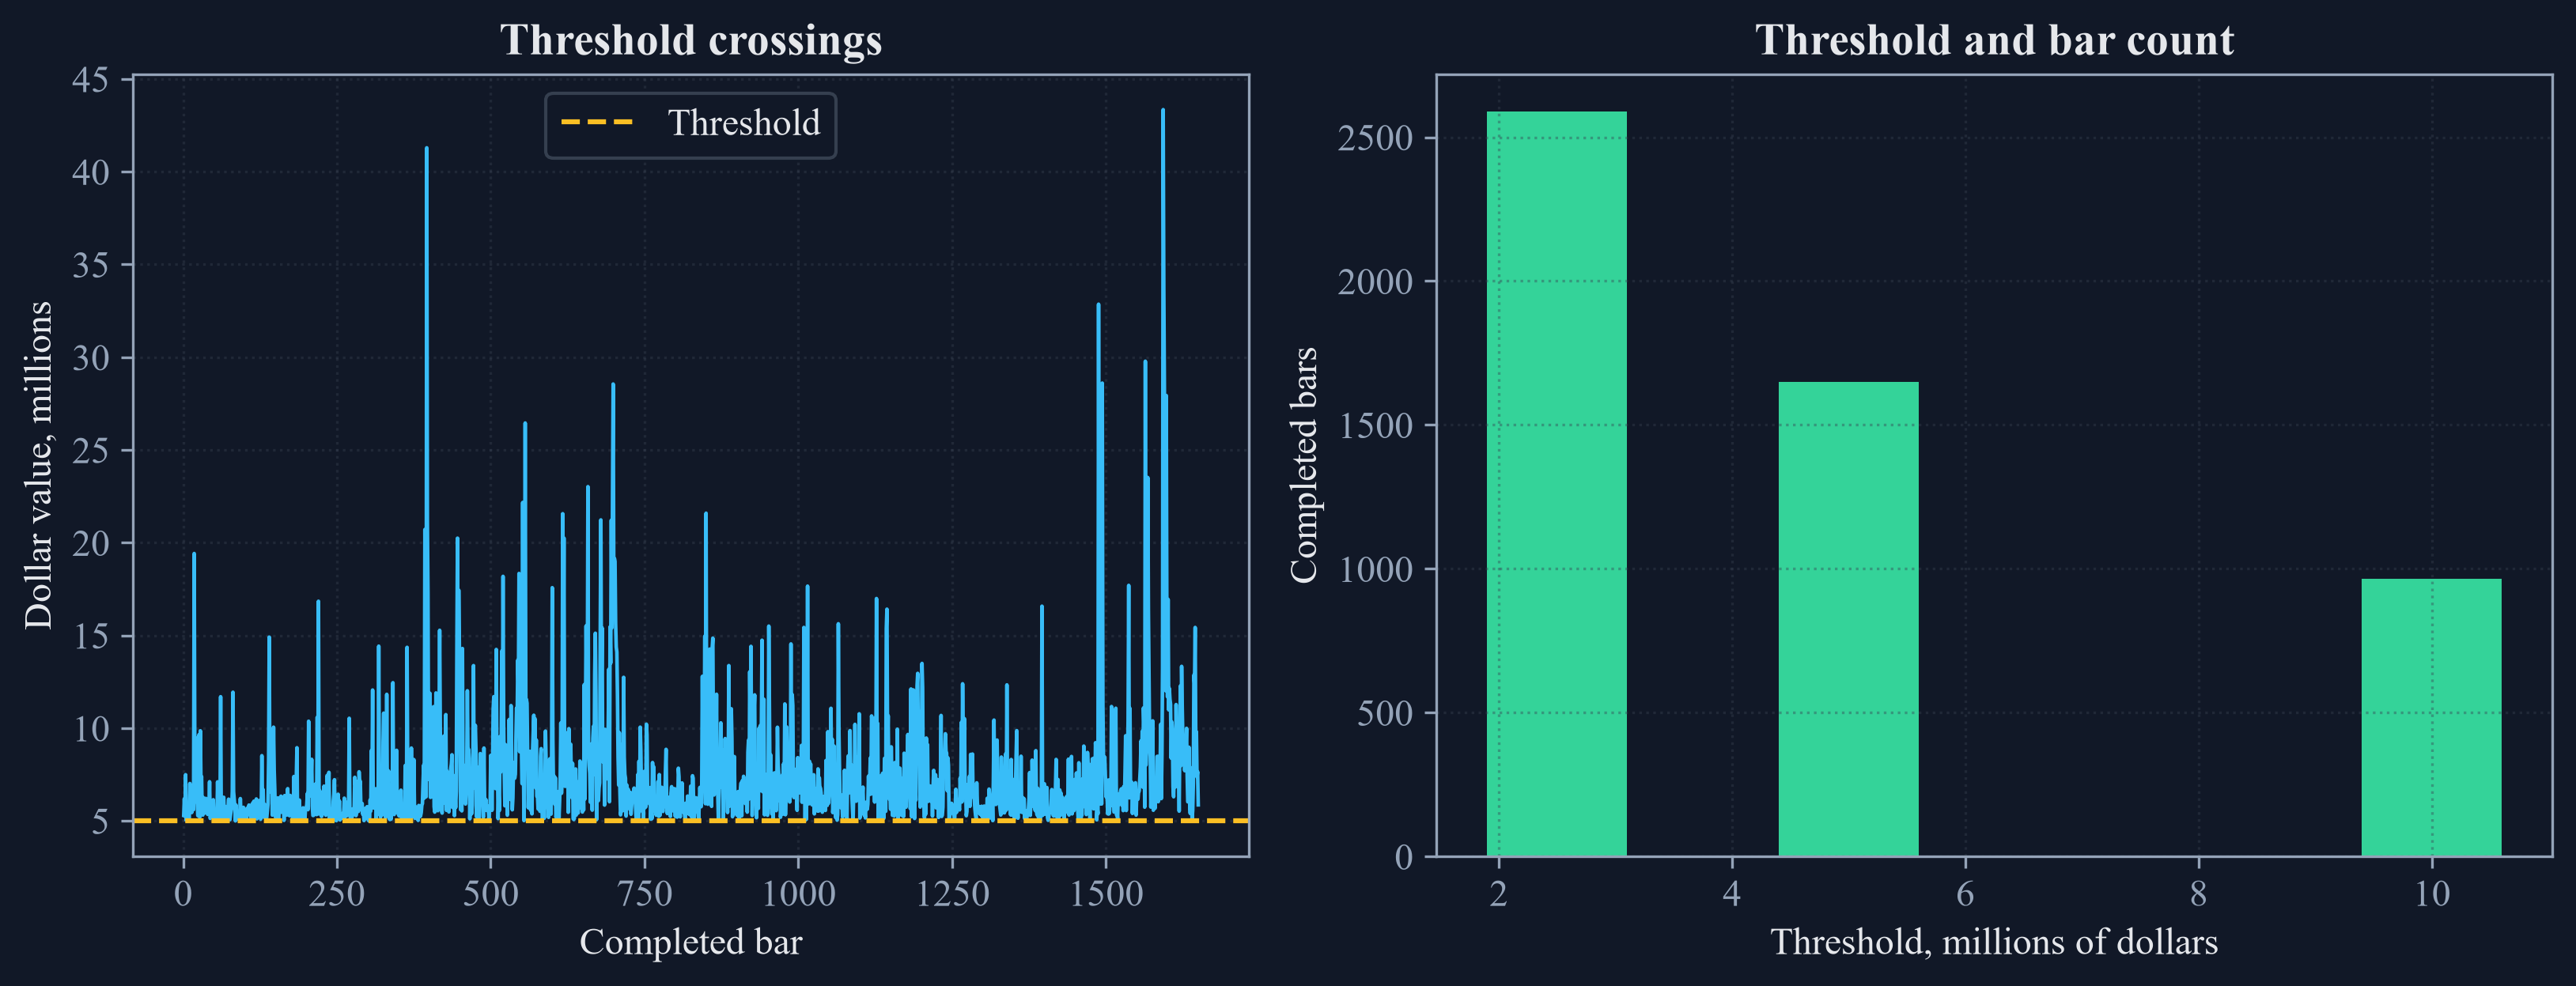

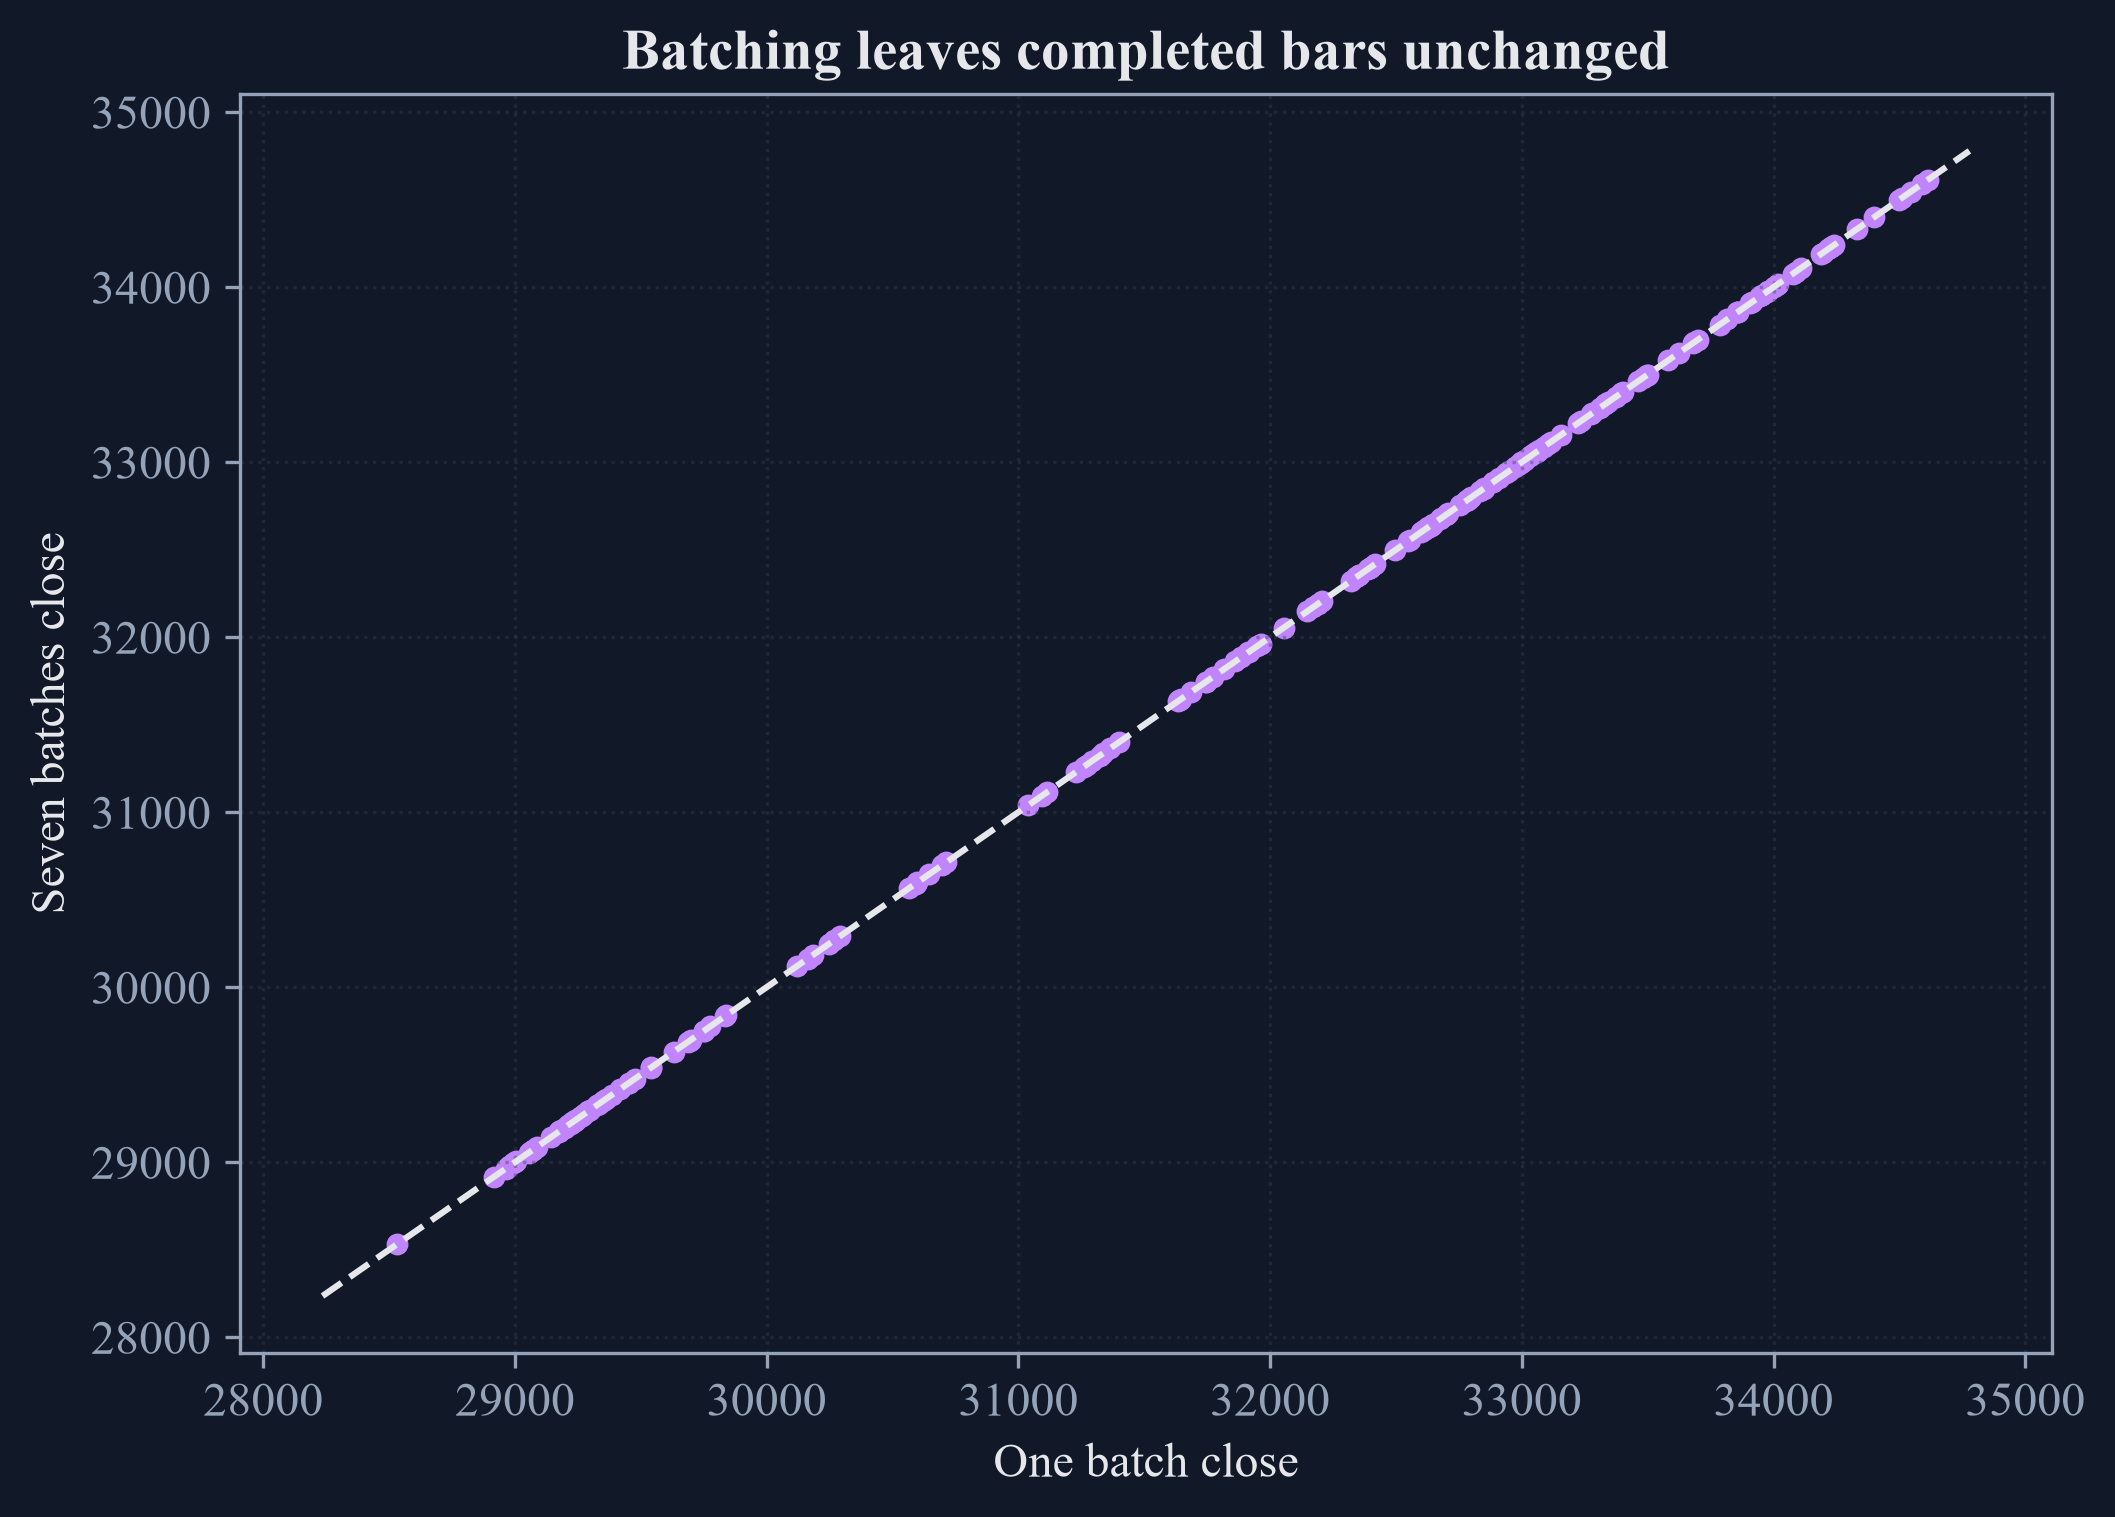

In [5]:
threshold = 5000000.0
one_batch = Controller().handle_input_command('dollar_standard_bars', {'threshold': threshold}, binance_rows, batch_size=len(binance_rows))
seven_batches = Controller().handle_input_command('dollar_standard_bars', {'threshold': threshold}, binance_rows, batch_size=715)
pd.testing.assert_frame_equal(one_batch.reset_index(drop=True), seven_batches.reset_index(drop=True))
batch_table = pd.DataFrame({'Input grouping': ['One batch', 'Seven batches'], 'Input rows': [len(binance_rows), len(binance_rows)], 'Completed bars': [len(one_batch), len(seven_batches)], 'Smallest completed dollar value': [one_batch['Cumulative Dollar Value'].min(), seven_batches['Cumulative Dollar Value'].min()], 'Last completed time': [one_batch['Date Time'].max(), seven_batches['Date Time'].max()]})
bar_data_provenance = pd.DataFrame({'Field': ['Archive', 'Provider', 'Records used', 'First minute', 'Last minute', 'Record meaning'], 'Value': [binance_path.name, 'Binance Data Vision', len(binance_rows), str(binance_rows['Date Time'].min()), str(binance_rows['Date Time'].max()), 'One-minute aggregate']})
threshold_rows = []
threshold_outputs = {}
for selected_threshold in (2500000.0, 5000000.0, 10000000.0):
    output = Controller().handle_input_command('dollar_standard_bars', {'threshold': selected_threshold}, binance_rows, batch_size=715)
    threshold_outputs[selected_threshold] = output
    threshold_rows.append({'Dollar threshold': selected_threshold, 'Completed bars': len(output), 'Mean rows per bar': len(binance_rows) / len(output), 'Smallest completed dollar value': output['Cumulative Dollar Value'].min(), 'Mean completed dollar value': output['Cumulative Dollar Value'].mean(), 'Greatest completed dollar value': output['Cumulative Dollar Value'].max()})
threshold_table = pd.DataFrame(threshold_rows)
save_table(bar_data_provenance, 'bar_data_provenance', 'Public minute archive used for the controller checks.', 'tab:chapter30-bar-provenance')
save_table(batch_table, 'batch_invariance', 'The same dollar bars from one input batch and seven input batches.', 'tab:chapter30-batch-invariance')
save_table(threshold_table, 'dollar_threshold_sensitivity', 'Completed dollar bars at three fixed thresholds.', 'tab:chapter30-threshold-sensitivity')
display(bar_data_provenance)
display(batch_table)
display(threshold_table)
figure, axes = plt.subplots(1, 2, figsize=(11.0, 4.3))
axes[0].plot(np.arange(1, len(one_batch) + 1), one_batch['Cumulative Dollar Value'] / 1000000.0, color=palette['cyan'], linewidth=1.1)
axes[0].axhline(threshold / 1000000.0, color=palette['amber'], linestyle='--', label='Threshold')
axes[0].set_xlabel('Completed bar')
axes[0].set_ylabel('Dollar value, millions')
axes[0].set_title('Threshold crossings')
axes[0].legend()
axes[1].bar(threshold_table['Dollar threshold'] / 1000000.0, threshold_table['Completed bars'], width=1.2, color=palette['green'])
axes[1].set_xlabel('Threshold, millions of dollars')
axes[1].set_ylabel('Completed bars')
axes[1].set_title('Threshold and bar count')
for axis in axes:
    axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, 'dollar_bar_thresholds')
comparison_positions = np.linspace(0, len(one_batch) - 1, min(200, len(one_batch))).astype(int)
figure, axis = plt.subplots(figsize=(7.2, 5.2))
axis.scatter(one_batch.iloc[comparison_positions]['Close'], seven_batches.iloc[comparison_positions]['Close'], color=palette['violet'], s=18)
bounds = [one_batch['Close'].min(), one_batch['Close'].max()]
axis.plot(bounds, bounds, color=palette['text'], linestyle='--')
axis.set_xlabel('One batch close')
axis.set_ylabel('Seven batches close')
axis.set_title('Batching leaves completed bars unchanged')
axis.grid(True, alpha=0.4)
figure.tight_layout()
save_figure(figure, 'batch_invariance')


## Handling invalid method names

In [6]:
invalid_output = Controller().handle_input_command("unknown bar choice", {}, binance_rows, batch_size=715)
invalid_table = pd.DataFrame({"Check": ["Unknown name", "Standard output columns", "Returned rows", "Complete input proved"], "Observed result": ["Rejected", len(invalid_output.columns), len(invalid_output), "No"]})
save_table(invalid_table, "invalid_controller_check", "Controller response to an unknown bar name.", "tab:chapter30-invalid-controller")
display(invalid_table)

Bar method 'unknown bar choice' not found. Valid methods are: ['expected_dollar_imbalance_bars', 'expected_volume_imbalance_bars', 'expected_tick_imbalance_bars', 'fixed_dollar_imbalance_bars', 'fixed_volume_imbalance_bars', 'fixed_tick_imbalance_bars', 'expected_dollar_run_bars', 'expected_volume_run_bars', 'expected_tick_run_bars', 'fixed_dollar_run_bars', 'fixed_volume_run_bars', 'fixed_tick_run_bars', 'dollar_standard_bars', 'volume_standard_bars', 'tick_standard_bars', 'time_bars']


,Check,Observed result
0,Unknown name,Rejected
1,Standard output columns,12
2,Returned rows,0
3,Complete input proved,No


## Tests

In [7]:
assert {family: len(names) for family, names in catalogue.items()} == {"bars": 6, "cross_validators": 6, "feature_importance": 5, "labelers": 0, "bet_sizers": 0, "portfolio_optimizers": 0}
assert len(bar_names) == 16
assert set(family_count_table["Family"]) == {"Imbalance", "Run", "Standard", "Time"}
assert labels.shape == (5000, 2)
assert label_metadata == {"family": "labeling", "horizon unit": "observations"}
assert duplicate_blocked
assert "direction_label" not in LABELERS and "future_direction" not in LABELERS
assert direct_object.apply(4.0) == 10.0
assert lazy_before and not lazy_after and counted["a"] == 5
assert len(one_batch) == len(seven_batches) == 1650
assert one_batch["Cumulative Dollar Value"].min() >= threshold
assert threshold_table["Completed bars"].is_monotonic_decreasing
assert invalid_output.empty and list(invalid_output.columns) == BAR_COLUMNS
display(pd.DataFrame({"Test": ["Catalog counts", "Sixteen bar names", "Four bar families", "Custom labels", "Metadata", "Duplicate protection", "Clean removal", "Direct construction", "Delayed construction", "Batch equality", "Threshold crossing", "Threshold monotonicity", "Invalid name"], "Passed": [True] * 13}))

,Test,Passed
0,Catalog counts,True
1,Sixteen bar names,True
2,Four bar families,True
3,Custom labels,True
4,Metadata,True
5,Duplicate protection,True
6,Clean removal,True
7,Direct construction,True
8,Delayed construction,True
9,Batch equality,True
